# Exploración de los boletines del SIPSA

Fase 2 de CRISP-DM: entender qué trae el boletín semanal, qué tan completo está y qué tanto se mueven los precios en Cavasa.

Corre primero `python main.py` para tener silver y gold.

In [1]:
import os
os.chdir('..')

import pandas as pd
import matplotlib.pyplot as plt

silver = pd.read_parquet('data/silver/precios.parquet')
gold = pd.read_parquet('data/gold/features.parquet')
silver.head()

,semana_inicio,semana_fin,anio,grupo,producto,mercado,precio_min,precio_max,precio_medio,tendencia,archivo
0,2023-05-27,2023-06-02,2023,Productos procesados,Aceite de palma,"Armenia, Mercar",10783.0,10850.0,10817.0,=,sipsa_0000002953.xlsx
1,2023-05-27,2023-06-02,2023,Productos procesados,Aceite de palma,"Cúcuta, Cenabastos",7667.0,8500.0,8028.0,+,sipsa_0000002953.xlsx
2,2023-05-27,2023-06-02,2023,Productos procesados,Aceite de palma,"Cúcuta, La Nueva Sexta",7250.0,7917.0,7500.0,+,sipsa_0000002953.xlsx
3,2023-05-27,2023-06-02,2023,Productos procesados,Aceite de palma,"Medellín, Central Mayorista de Antioquia",9074.0,9630.0,9363.0,-,sipsa_0000002953.xlsx
4,2023-05-27,2023-06-02,2023,Productos procesados,Aceite de palma,"Montería, Mercado del Sur",6481.0,7222.0,6991.0,-,sipsa_0000002953.xlsx


## Cobertura

In [2]:
print('Filas:', len(silver))
print('Semanas:', silver['semana_inicio'].nunique(), '|', silver['semana_inicio'].min().date(), 'a', silver['semana_inicio'].max().date())
print('Mercados:', silver['mercado'].nunique())
print('Productos:', silver['producto'].nunique())
silver.groupby('grupo')['producto'].nunique().sort_values()

Filas: 785975
Semanas: 177 | 2023-05-27 a 2026-10-31
Mercados: 92
Productos: 363


grupo
Huevos y lácteos                 14
Granos y cereales                38
Tubérculos, raíces y plátanos    38
Pescados                         39
Productos procesados             44
Carnes                           45
Verduras y hortalizas            66
Frutas frescas                   79
Name: producto, dtype: int64

¿Faltan semanas?

In [3]:
weeks = silver['semana_inicio'].drop_duplicates().sort_values()
gaps = weeks[weeks.diff().dt.days > 7]
print('Semanas después de un hueco:', [str(d.date()) for d in gaps])

Semanas después de un hueco: ['2026-01-03', '2026-09-05', '2026-10-03']


## Mercados de Cali

Santa Elena reporta más productos porque también es una plaza de mercado minorista. Cavasa es la central mayorista donde se surten los restaurantes y las galerías, por eso es el mercado del MVP. Tiene 65 productos, de sobra para los 20 que se eligieron.

In [4]:
silver[silver['mercado'].str.startswith('Cali')].groupby('mercado')['producto'].nunique().sort_values(ascending=False)

mercado
Cali, Santa Elena        138
Cali, Cavasa              65
Cali, Siloé               38
Cali, La Floresta         37
Cali, Galería Alameda     29
Name: producto, dtype: int64

## ¿Qué tanto se mueven los precios en Cavasa?

clase
baja       0.365
sube       0.357
estable    0.279
Name: proportion, dtype: float64


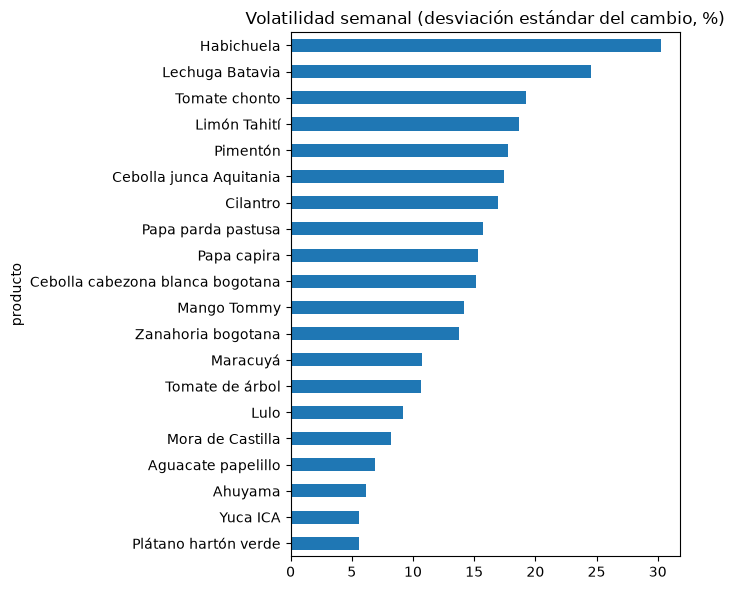

In [5]:
changes = gold.dropna(subset=['cambio_siguiente'])
print(changes['clase'].value_counts(normalize=True).round(3))
(changes.groupby('producto')['cambio_siguiente'].std() * 100).sort_values().plot.barh(figsize=(7, 6), title='Volatilidad semanal (desviación estándar del cambio, %)')
plt.tight_layout()

Más de dos tercios de las semanas un producto sube o baja más de 3 %. Los más volátiles son la habichuela, la lechuga y el tomate chonto, que se mueven más de 19 % por semana. Los más estables son el plátano, la yuca y la ahuyama, alrededor de 6 %.

## Cavasa contra el resto del país

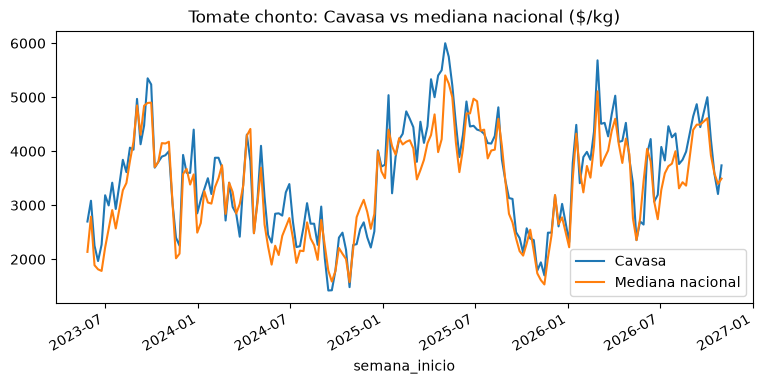

In [6]:
p = gold[gold['producto'] == 'Tomate chonto']
ax = p.plot(x='semana_inicio', y=['precio', 'precio_nacional'], figsize=(9, 4), title='Tomate chonto: Cavasa vs mediana nacional ($/kg)')
ax.legend(['Cavasa', 'Mediana nacional']);

In [7]:
# ¿El cambio nacional de esta semana anticipa el cambio de Cavasa la próxima?
c = gold.dropna(subset=['cambio_nacional_1s', 'cambio_siguiente'])
print('Correlación:', round(c['cambio_nacional_1s'].corr(c['cambio_siguiente']), 3))
print('Correlación con su propio cambio pasado:', round(c['cambio_1s'].corr(c['cambio_siguiente']), 3))

Correlación: 0.039
Correlación con su propio cambio pasado: -0.085


## Conclusiones para la preparación de datos

- La semana se toma del título del índice; tiene formatos distintos y semanas cortas por festivos.
- Hay productos repetidos dentro del mismo boletín: hay que deduplicar.
- Faltan algunas semanas: el objetivo solo se calcula cuando la siguiente está a 7 días.
- La relación lineal entre el cambio nacional y el próximo cambio de Cavasa es débil (0,04). Aun así, entra como variable para que el modelo la combine con las demás. Al final quedó entre las más importantes del Random Forest.
- El DANE cambió el nombre de un grupo ("Lácteos y huevos" / "Huevos y lácteos"); se unifica en silver.